# 9.3 Удержание и когорты — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 09 «Продуктовые метрики и события» · страница 9.3.

Посчитаем три вида недельного удержания в pandas, затем построим тепловую карту и кривые когорт. Отдельный файл `cohorts.sql` содержит запрос к той же выборке для PostgreSQL.

Выполняйте ячейки по порядку. Для построения графиков понадобятся таблицы, которые мы рассчитаем в первой части.

Вывод получен на Python 3.13, pandas 3.0, pyarrow 26 и matplotlib 3.10.

## Где лежат данные

Распакуйте общий набор рядом с папкой урока. Первая ячейка найдёт `data/events/events.parquet` и `data/events/users.csv` и установит рабочую папку. Туда же будут сохранены `heatmap.svg` и `curves.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import pandas as pd
import pyarrow

root = pathlib.Path.cwd()
while not (root / "data" / "events").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/events/
assert (root / "data" / "events" / "events.parquet").exists(), \
    "Не найдена папка data/events/. Скачайте общий набор темы 09 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| pyarrow", pyarrow.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.13 | pandas 3.0.5 | pyarrow 26.0.1 | matplotlib 3.10.9


## Три вида удержания и графики когорт

### Три вида удержания из одной таблицы

In [2]:
import pandas as pd

START, LAST = pd.Timestamp("2026-01-05"), pd.Timestamp("2026-06-28")
minsk_day = lambda s: s.dt.tz_convert("Europe/Minsk").dt.tz_localize(None).dt.normalize()

# таблица «пользователь — день», как в 9.1: без дублей, без ботов, склейка, минский день
ev = pd.read_parquet("data/events/events.parquet").drop_duplicates("event_id")
ev["day"] = minsk_day(ev["event_time"])
per_day = ev[ev["origin"] == "client"].groupby(["anonymous_id", "day"]).size()
bots = per_day[per_day > 100].index.get_level_values("anonymous_id").unique()
ev = ev[~ev["anonymous_id"].isin(bots)]
account = ev.dropna(subset=["anonymous_id", "user_id"]).groupby("anonymous_id")["user_id"].first()
ev["person"] = ev["user_id"].fillna(ev["anonymous_id"].map(account)).fillna(ev["anonymous_id"])
ud = ev.loc[ev["day"].between(START, LAST), ["person", "day"]].drop_duplicates()

# когорта — неделя прихода (первый день или регистрация, что раньше); старые аккаунты — не новички
users = pd.read_csv("data/events/users.csv", parse_dates=["signup_time"]).set_index("user_id")
first = ud.groupby("person")["day"].min()
arrived = pd.concat([first, minsk_day(users["signup_time"]).reindex(first.index)], axis=1).min(axis=1)
week = lambda d: (d - START).dt.days // 7               # 0 = неделя 5 января
cohort = week(arrived[arrived >= START])
size = cohort.value_counts().sort_index()

act = ud[ud["person"].isin(cohort.index)].assign(c=lambda d: d["person"].map(cohort))
act["n"] = week(act["day"]) - act["c"]
act = act[act["n"] >= 1].drop_duplicates(["person", "n"])  # неделя 0 — сам приход

N = range(1, 25)
classic = act.groupby(["c", "n"])["person"].nunique().unstack(fill_value=0).reindex(columns=N, fill_value=0)
per_person = act.groupby("person")["n"].agg(["min", "max"]).join(cohort.rename("c"))
by_last = pd.crosstab(per_person["c"], per_person["max"]).reindex(columns=N, fill_value=0)
by_first = pd.crosstab(per_person["c"], per_person["min"]).reindex(columns=N, fill_value=0)
rolling = by_last.loc[:, ::-1].cumsum(axis=1).loc[:, ::-1]   # активен в неделю n или позже
returned = by_first.cumsum(axis=1)                            # хотя бы раз за недели 1…n

lived = pd.DataFrame({n: size.index + n <= 24 for n in N}, index=size.index)  # неделя n уже прошла
share = lambda m: (100 * m.div(size, axis=0)).where(lived).round(1).rename_axis(columns="n")
types = {"классическое": share(classic), "скользящее": share(rolling), "возвратное": share(returned)}

rows = [10, 13, 21]                                       # 16 марта, 6 апреля, 1 июня
for name, m in types.items():
    print(f"{name}, % когорты:")
    print(m.loc[rows, 1:7].set_axis([f"{START + pd.Timedelta(weeks=c):%d.%m}" for c in rows]).to_string(), "\n")

hero = act.loc[act["person"] == "u_03753", "n"].tolist()
print("u_03753 возвращался в недели", hero)
print("n:          ", *range(1, 9))
print("классическое", *[int(n in hero) for n in range(1, 9)])
print("скользящее  ", *[int(max(hero) >= n) for n in range(1, 9)])
print("возвратное  ", *[int(min(hero) <= n) for n in range(1, 9)])

классическое, % когорты:
n         1     2     3     4     5     6     7
16.03  34.7  25.3  22.7  21.4  21.4  19.8  16.6
06.04  28.4  20.5  14.6  16.2  12.7  16.0  15.0
01.06  34.8  26.3  22.3   NaN   NaN   NaN   NaN 

скользящее, % когорты:
n         1     2     3     4     5     6     7
16.03  71.4  67.5  65.9  63.6  60.4  59.1  55.8
06.04  61.1  56.3  53.0  50.6  46.8  44.8  40.4
01.06  50.0  38.0  22.3   NaN   NaN   NaN   NaN 

возвратное, % когорты:
n         1     2     3     4     5     6     7
16.03  34.7  44.5  50.3  53.9  58.4  61.4  63.3
06.04  28.4  36.3  41.3  46.0  48.2  52.3  54.0
01.06  34.8  43.4  50.0   NaN   NaN   NaN   NaN 

u_03753 возвращался в недели [2, 3, 7]
n:           1 2 3 4 5 6 7 8
классическое 0 1 1 0 0 0 1 0
скользящее   1 1 1 1 1 1 1 0
возвратное   0 1 1 1 1 1 1 1


Для когорты 1 июня последняя доступная неделя — третья. Поэтому на этой неделе классическое и скользящее удержание совпадают.

### Удержание по неделям и группам когорт

In [3]:
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({"svg.fonttype": "none", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
ACCENT, CAMP, DARK, GREY = "#0d7468", "#c2417a", "#454f62", "#9aa3b2"
teal = LinearSegmentedColormap.from_list("teal", ["#f5f6f8", ACCENT])   # один тон: темнее — больше
m = types["классическое"].loc[:, 1:12]                                  # 25 когорт × недели 1–12
labels = [f"{START + pd.Timedelta(weeks=c):%d.%m}" for c in m.index]

# 1. Тепловая карта: строка — когорта, столбец — неделя жизни
fig, ax = plt.subplots(figsize=(6.4, 6), layout="constrained")
im = ax.imshow(m.to_numpy(), cmap=teal, vmin=0, vmax=40, aspect="auto", interpolation="nearest",
               extent=(0.5, 12.5, len(m) - 0.5, -0.5))                 # растр 25 × 12 весит в SVG мало
ax.hlines([y + 0.5 for y in range(len(m) - 1)], 0.5, 12.5, color="white", linewidth=0.6)
ax.vlines([x + 0.5 for x in range(1, 12)], -0.5, len(m) - 0.5, color="white", linewidth=0.6)
ax.set(xticks=list(m.columns), yticks=range(len(m)), yticklabels=labels, xlabel="неделя жизни когорты n")
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.axhline(9.5, color="#141a24", linewidth=1)                         # события — подписью на месте
ax.annotate("релиз 3.0", (12.5, 9.5), xytext=(6, 0), textcoords="offset points", va="center")
ax.plot([12.8, 12.8], [12.6, 16.4], color=CAMP, linewidth=2, clip_on=False)
ax.annotate("кампания", (12.8, 14.5), xytext=(6, 0), textcoords="offset points", va="center", color=CAMP,
            annotation_clip=False)
ax.set_xlim(0.5, 12.5)
fig.colorbar(im, ax=ax, shrink=0.45, location="bottom", label="% когорты, активной в неделю n")
fig.suptitle("Доля вернувшихся выше у мартовских когорт\nпосле релиза", x=0.02, ha="left",
             fontweight="bold", fontsize=11)
ax.set_title("Классическое удержание. В пустых ячейках неделя ещё не закончилась",
             loc="left", fontsize=8, color="#737c8f")
fig.savefig("heatmap.svg")

# 2. Кривые: каждая когорта — серая линия, три группы — взвешенное среднее с прямой подписью
cnt = classic.loc[:, 1:12]
groups = {"до релиза": (range(0, 10), DARK, (6, 0)), "16–30 марта": (range(10, 13), ACCENT, (6, 0)),
          "кампания": (range(13, 17), CAMP, (-10, -34))}
fig, ax = plt.subplots(figsize=(6.4, 3.8), layout="constrained")
for c in m.index:
    ax.plot(m.columns, m.loc[c], color=GREY, linewidth=0.6, alpha=0.6)
for name, (rows, color, offset) in groups.items():
    rows = list(rows)
    w = cnt.loc[rows].sum() / size[rows].sum() * 100                  # все вернувшиеся / все пришедшие
    w = w[m.loc[rows].notna().all()]                                 # только недели, прожитые всеми
    ax.plot(w.index, w, color=color, linewidth=2.2)
    ax.annotate(f"{name}: плато {w.loc[4:9].mean():.1f}%".replace(".", ","), (w.index[-1], w.iloc[-1]),
                xytext=offset, textcoords="offset points", va="center", color=color, fontweight="bold",
                arrowprops=None if offset[1] == 0 else {"arrowstyle": "-", "color": color, "linewidth": 0.8})
ax.axvspan(4, 9, color="#edf0f4", zorder=0)
ax.text(6.5, 35, "плато: недели 4–9", ha="center", color="#737c8f")
ax.set(xlim=(1, 12), ylim=(0, 40), xticks=range(1, 13), xlabel="неделя жизни когорты n", ylabel="% когорты")
fig.suptitle("После релиза плато выше: 19% у мартовских когорт", x=0.02, ha="left",
             fontweight="bold", fontsize=11)
ax.set_title("Тонкие линии — отдельные когорты. Источник: учебный журнал событий",
             loc="left", fontsize=7.5, color="#737c8f")
fig.savefig("curves.svg")
print({f: round(os.path.getsize(f) / 1024, 1) for f in ["heatmap.svg", "curves.svg"]}, "КБ")

{'heatmap.svg': 32.6, 'curves.svg': 28.2} КБ


Выполните предыдущую ячейку, чтобы получить types, classic, size и START. Код сохранит тепловую карту и кривые в двух файлах SVG.

Matplotlib сохранил графики в рабочей папке. Следующая ячейка покажет оба файла прямо в ноутбуке.

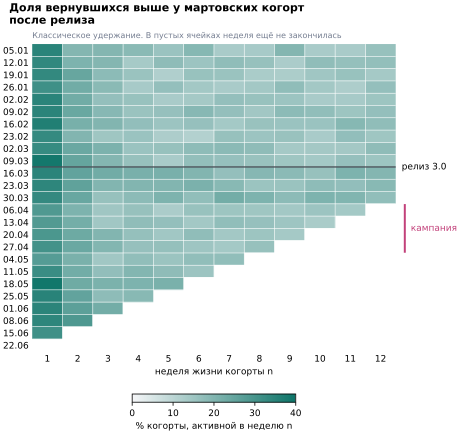

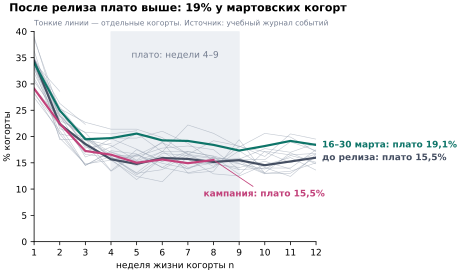

In [4]:
from IPython.display import SVG, display

display(SVG("heatmap.svg"), SVG("curves.svg"))